# Biomomentum preprocessing with PID steady-force segmentation

Read each TXT file in `data/Biomomentum_Data/txts/`, identify when the PID-controlled force reaches a steady holding regime, and export only the corresponding continuous force and displacement interval. Run all cells in the **Dataprocess** environment with NumPy, pandas, Matplotlib, and IPython. Existing CSV files with matching names in `data/Biomomentum_Data/` are overwritten by the export cell.

Every output has exactly three ordered columns: **`Time, s`**, **`Indentation Position, mm`**, and **`Indentation Force, N`**. Use `Position (z), mm` as indentation and invert `Fz, N` so compression is positive. Reset **time only** to zero at the first steady-force sample; retain measured displacement and force, including PID oscillations. Do not filter, resample, or independently zero either measured signal.

A steady PID force can oscillate around its holding level. Detect the holding regime using a multi-period window mean and regression trend, with a separate allowance for force variation. Keep every sample within one continuous selected interval, including oscillation peaks and troughs. Review the plots before export. `_steady_state_manifest.csv` records original boundaries, holding forces, and detection settings. Raw TXT files are read only.

In [1]:
import csv
import math
import sys

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from pathlib import Path

def find_project_root(start):
    # Support running from the project root, data_process, or this notebook directory.
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'Biomomentum_Data' / 'txts').is_dir():
            return candidate
    raise FileNotFoundError('Could not find data/Biomomentum_Data/txts. Start the notebook within the project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data' / 'txts'
OUTPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data'
sys.path.insert(0, str(PROJECT_ROOT / 'data_process' / 'utils'))
from creep_force_preprocessing import segment_force_steady_state, extract_indentation_cycles

SAMPLING_HZ = 200.0
PID_STEADY_STATE_SETTINGS = dict(
    stability_window_s=2.0, stable_confirm_s=1.0, plateau_tail_s=5.0,
    level_tolerance_fraction=0.02, stable_std_fraction=0.05,
    stable_slope_fraction=0.01, release_guard_s=0.0, min_force_n=0.2,
)

EXTRACT_COLUMNS = [
    'Time, s',
    'Position (z), mm',
    'Fz, N',
]

EXTRACT_COLUMNS_SIGNS = [
    1.0,
    1.0,
    -1.0,
]

OUTPUT_COLUMNS = [
    'Time, s',
    'Indentation Position, mm',
    'Indentation Force, N',
]

if len(EXTRACT_COLUMNS) != len(OUTPUT_COLUMNS):
    raise ValueError(f'EXTRACT_COLUMNS and OUTPUT_COLUMNS must have the same length. '
                     f'Found {len(EXTRACT_COLUMNS)} and {len(OUTPUT_COLUMNS)}.')

if len(EXTRACT_COLUMNS_SIGNS) != len(EXTRACT_COLUMNS):
    raise ValueError('EXTRACT_COLUMNS_SIGNS must contain one sign per extracted column.')
if any(not math.isfinite(sign) or sign not in (-1.0, 1.0) for sign in EXTRACT_COLUMNS_SIGNS):
    raise ValueError('Extraction signs must be finite and equal to +1 or -1.')
if EXTRACT_COLUMNS_SIGNS[0] != 1.0:
    raise ValueError('Keep the time sign at +1 so timestamps remain increasing.')

print(f'Input directory: {INPUT_DIR}')
print(f'Output directory: {OUTPUT_DIR}')

Input directory: /home/erielab/Git_repo/Hoang_Tonometry_Control_Code/data/Biomomentum_Data/txts
Output directory: /home/erielab/Git_repo/Hoang_Tonometry_Control_Code/data/Biomomentum_Data


## Read data sections

Extract only the selected columns between `<DATA>` and `<END DATA>`, using the column names rather than axis order. Validate finite numeric values before applying the configured signs. Preserve all selected measurements for segmentation and comparison plots.

In [2]:
def read_biomomentum_txt(txt_path):
    txt_path = Path(txt_path)
    rows = []
    in_data = False
    header = None
    block_rows = 0

    def invalid(line_number, message):
        return ValueError(f'{txt_path.name}:{line_number}: {message}')

    with txt_path.open('r', encoding='utf-8-sig', newline='') as handle:
        for line_number, fields in enumerate(csv.reader(handle, delimiter='\t'), start=1):
            fields = [field.strip() for field in fields]
            if not fields or not any(fields):
                continue
            marker = fields[0]
            if marker == '<DATA>':
                if in_data:
                    raise invalid(line_number, 'The previous data section is missing <END DATA>.')
                in_data, header, block_rows = True, None, 0
                continue
            if not in_data:
                continue
            if marker == '<END DATA>':
                if header is None or block_rows == 0:
                    raise invalid(line_number, 'The data section is empty.')
                in_data = False
                continue
            if header is None:
                header = fields
                missing = [column for column in EXTRACT_COLUMNS if column not in header]
                if missing:
                    raise invalid(line_number, f'Missing columns: {missing}')
                if len(header) != len(set(header)):
                    raise invalid(line_number, 'The header contains duplicate column names.')
                column_indices = [header.index(column) for column in EXTRACT_COLUMNS]
                continue
            if len(fields) != len(header):
                raise invalid(line_number, f'Expected {len(header)} columns, found {len(fields)}.')
            selected = [fields[index] for index in column_indices]
            for column, value in zip(EXTRACT_COLUMNS, selected):
                try:
                    numeric_value = float(value)
                except ValueError as exc:
                    raise invalid(line_number, f'{column} contains a nonnumeric value: {value!r}') from exc
                if not math.isfinite(numeric_value):
                    raise invalid(line_number, f'{column} contains a nonfinite value: {value!r}')
            rows.append(selected)
            block_rows += 1

    if in_data:
        raise ValueError(f'{txt_path.name}: Reached the end of the file without finding <END DATA>.')
    if not rows:
        raise ValueError(f'{txt_path.name}: No valid <DATA> section was found.')
    
    for row in rows:
        for column, sign, value in zip(EXTRACT_COLUMNS, EXTRACT_COLUMNS_SIGNS, row):
            numeric_value = float(value)
            numeric_value *= sign
            row[EXTRACT_COLUMNS.index(column)] = numeric_value
    return rows

## Validate all input files

Read every TXT before selecting intervals or writing CSVs. Each recording is treated as one loading-and-hold interval. Require continuous 200 Hz timestamps; multiple concatenated data blocks with restarted times or missing samples raise an error instead of being joined into a false continuous record.

In [3]:
txt_files = sorted(
    path for path in INPUT_DIR.iterdir()
    if path.is_file() and path.suffix.lower() == '.txt'
)
if not txt_files:
    raise FileNotFoundError(f'No TXT files were found in the input directory: {INPUT_DIR}')

# Validate all inputs before writing to avoid partial updates caused by malformed TXT files.
extracted = [(path, read_biomomentum_txt(path)) for path in txt_files]

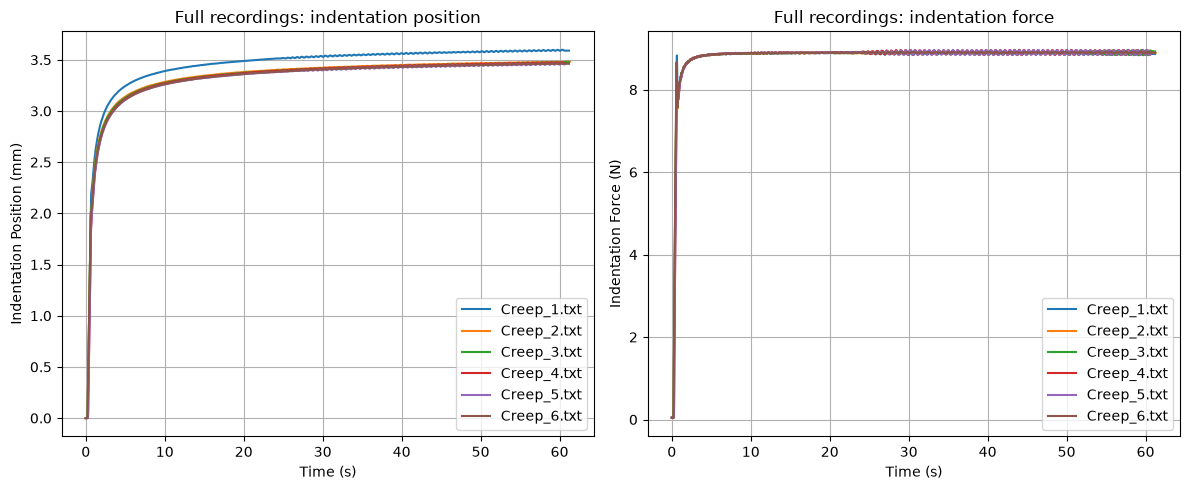

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for file, data in extracted:
    time = [float(row[0]) for row in data]
    position = [float(row[1]) for row in data]
    force = [float(row[2]) for row in data]

    axes[0].plot(time, position, label=file.name)
    axes[1].plot(time, force, label=file.name)

# Position subplot
axes[0].set_title('Full recordings: indentation position')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Indentation Position (mm)')
axes[0].legend()
axes[0].grid(True)

# Force subplot
axes[1].set_title('Full recordings: indentation force')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Indentation Force (N)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
plt.close(fig)

## Segment force reaching steady state with PID oscillation

Estimate the holding force from the median of the last **5 s**. Over a full trailing **2 s** window, require the mean within **2%** of that level, a force standard deviation no greater than **5%** of the level, and an absolute regression slope no greater than **1% of the holding force per second**. The 2 s window spans several of the approximately 0.6 s PID oscillations in these recordings; the variation allowance does not require a flat instantaneous force. Adjust `PID_STEADY_STATE_SETTINGS` if the controller oscillation period or amplitude changes.

Confirm the conditions continuously for **1 s**, and start at the first qualifying window endpoint in that run. Retain one continuous interval through the recording end, or stop earlier at the beginning of a later sustained loss of stability. Brief fluctuations and all bounded oscillation samples remain. No pointwise force threshold is applied to exported rows. These TXT recordings contain no release segment, so `release_guard_s` is zero; if future recordings include unloading, bound the hold before applying this detector.

The rolling statistics select boundaries only. Force and displacement remain unchanged, with their original alignment and amplitude. A recording without a confirmed steady interval raises an error before any exports are written.

In [5]:
steady_extracted = []
segmentation_results = []
manifest_rows = []
for txt_path, rows in extracted:
    values = np.asarray(rows, dtype=float)
    sync = pd.DataFrame({
        'time_s': values[:, 0],
        'displacement_mm': values[:, 1],
        'force_n': values[:, 2],
    })
    cycle = pd.DataFrame([{
        'cycle': 1, 'onset_s': values[0, 0],
        'release_s': values[-1, 0] + 1.0 / SAMPLING_HZ,
    }])
    try:
        bounds = segment_force_steady_state(sync, cycle, **PID_STEADY_STATE_SETTINGS)
        _, frame = extract_indentation_cycles(
            sync, bounds, sampling_hz=SAMPLING_HZ, steady_only=True,
        )[0]
    except ValueError as exc:
        raise ValueError(f'{txt_path.name}: {exc}') from exc
    event = bounds.iloc[0]
    steady_extracted.append((txt_path, frame))
    segmentation_results.append(dict(path=txt_path, sync=sync, bounds=bounds, frame=frame))
    manifest_rows.append({
        'file': f'{txt_path.stem}.csv',
        'source_txt': str(txt_path.relative_to(PROJECT_ROOT)),
        'export_scope': 'steady_force_only',
        'original_start_s': values[0, 0], 'original_last_sample_s': values[-1, 0],
        'steady_start_s': event.steady_start_s, 'steady_end_s': event.steady_end_s,
        'steady_force_n': event.steady_force_n,
        'rows': len(frame), 'duration_s': frame[OUTPUT_COLUMNS[0]].iloc[-1],
        'sampling_hz': SAMPLING_HZ,
        'force_std_n': frame[OUTPUT_COLUMNS[2]].std(ddof=0),
        'force_peak_to_peak_n': np.ptp(frame[OUTPUT_COLUMNS[2]].to_numpy()),
        'position_sign': EXTRACT_COLUMNS_SIGNS[1], 'force_sign': EXTRACT_COLUMNS_SIGNS[2],
        **{f'pid_{key}': value for key, value in PID_STEADY_STATE_SETTINGS.items()},
    })

steady_summary = pd.DataFrame(manifest_rows)
display(steady_summary[['file', 'steady_start_s', 'steady_force_n',
                        'force_std_n', 'rows', 'duration_s']])

,file,steady_start_s,steady_force_n,force_std_n,rows,duration_s
0,Creep_1.csv,3.820,8.891996,0.025703,11476,57.375
1,Creep_2.csv,3.850,8.895464,0.013395,11490,57.445
2,Creep_3.csv,3.815,8.926676,0.019573,11477,57.380
3,Creep_4.csv,3.835,8.912804,0.033863,11373,56.860
4,Creep_5.csv,3.875,8.909336,0.032406,11365,56.820
5,Creep_6.csv,3.805,8.902400,0.014108,11479,57.390


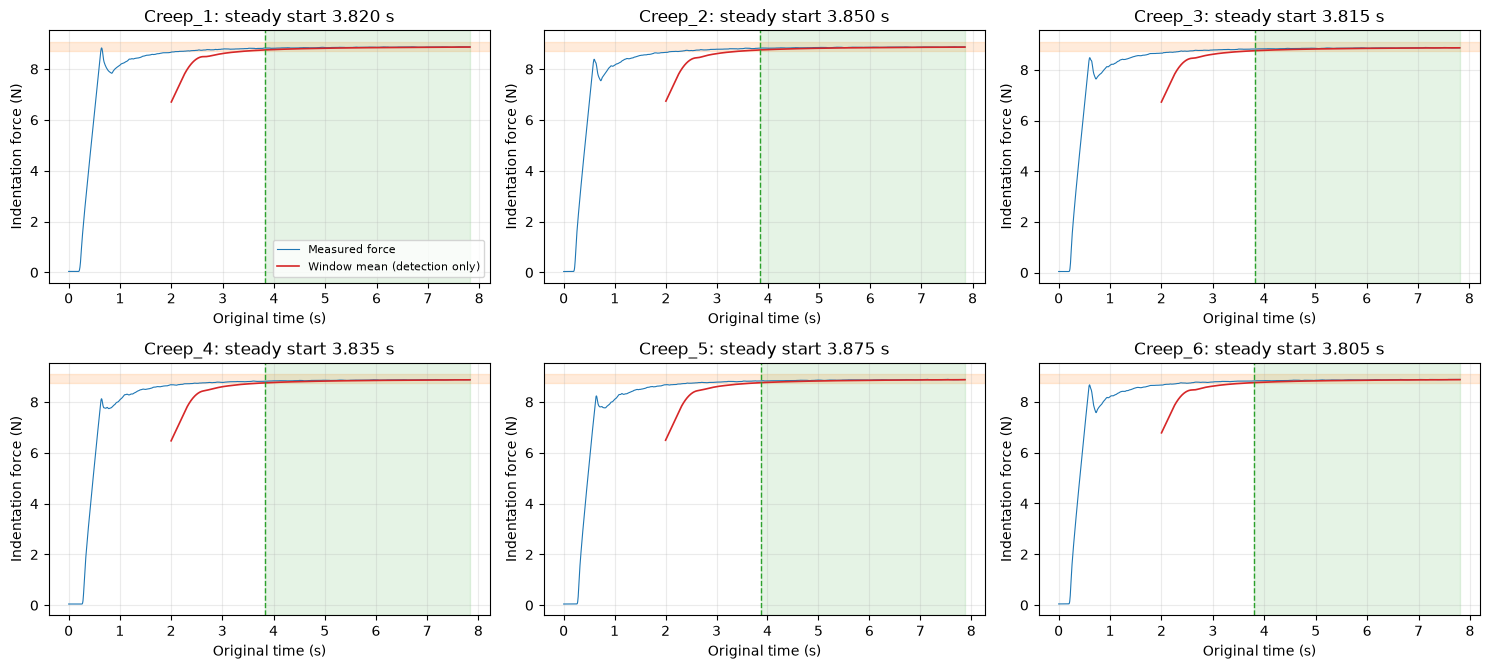

In [6]:
ncols = min(3, len(segmentation_results))
nrows = math.ceil(len(segmentation_results) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows), squeeze=False)
for axis, result in zip(axes.flat, segmentation_results):
    sync = result['sync']
    event = result['bounds'].iloc[0]
    dt = float(np.median(np.diff(sync.time_s)))
    window = max(3, int(np.ceil(PID_STEADY_STATE_SETTINGS['stability_window_s'] / dt)))
    force_mean = sync.force_n.rolling(window, min_periods=window).mean()
    view_end = min(event.steady_end_s, event.steady_start_s + 4.0)
    view = sync.time_s <= view_end
    axis.plot(sync.loc[view, 'time_s'], sync.loc[view, 'force_n'], lw=0.8,
              color='tab:blue', label='Measured force')
    axis.plot(sync.loc[view, 'time_s'], force_mean[view], lw=1.2,
              color='tab:red', label='Window mean (detection only)')
    level = event.steady_force_n
    tolerance = PID_STEADY_STATE_SETTINGS['level_tolerance_fraction'] * level
    axis.axhspan(level - tolerance, level + tolerance, color='tab:orange', alpha=0.15)
    axis.axvspan(event.steady_start_s, view_end, color='tab:green', alpha=0.12)
    axis.axvline(event.steady_start_s, color='tab:green', ls='--', lw=1)
    axis.set(title=f"{result['path'].stem}: steady start {event.steady_start_s:.3f} s",
             xlabel='Original time (s)', ylabel='Indentation force (N)')
    axis.grid(True, alpha=0.25)
axes.flat[0].legend(fontsize=8)
for axis in list(axes.flat)[len(segmentation_results):]:
    axis.set_visible(False)
fig.tight_layout()
plt.show()
plt.close(fig)

## Inspect retained force and displacement

The comparison below uses only the selected intervals, with time zero at each steady-force start. Force oscillations are intentionally visible and preserved. No displacement offset is removed, and position and force always retain the same sample count and timestamps.

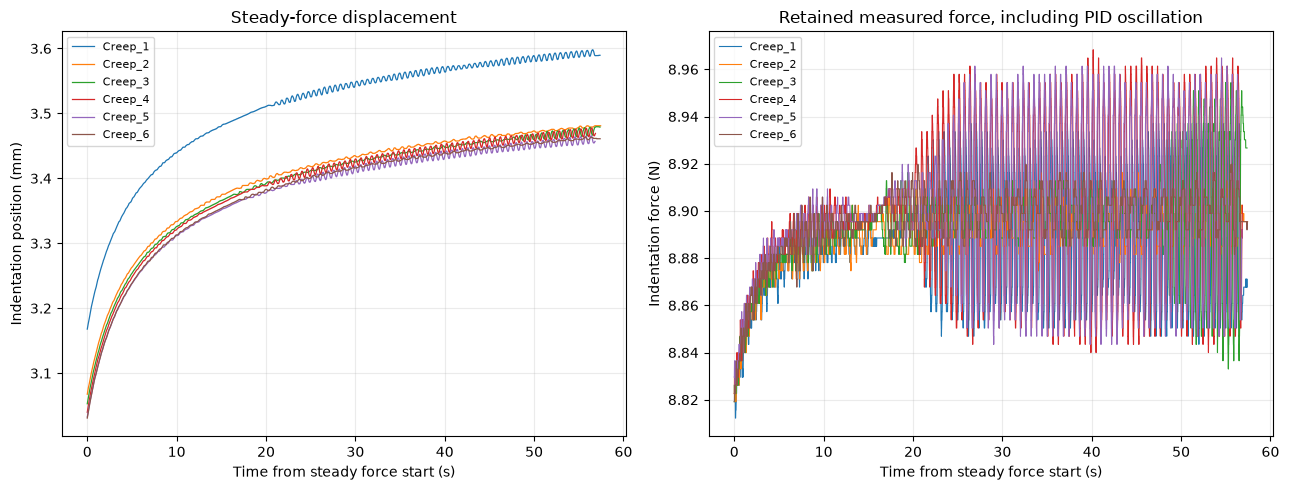

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for txt_path, frame in steady_extracted:
    time = frame[OUTPUT_COLUMNS[0]]
    line, = axes[0].plot(time, frame[OUTPUT_COLUMNS[1]], lw=0.9, label=txt_path.stem)
    axes[1].plot(time, frame[OUTPUT_COLUMNS[2]], lw=0.8, color=line.get_color(), label=txt_path.stem)
axes[0].set(title='Steady-force displacement', ylabel='Indentation position (mm)')
axes[1].set(title='Retained measured force, including PID oscillation', ylabel='Indentation force (N)')
for axis in axes:
    axis.set_xlabel('Time from steady force start (s)')
    axis.grid(True, alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## Export steady-force CSVs

All inputs and selected intervals are validated before writing. Each CSV contains exactly the three configured columns without a row index. Running this cell overwrites matching exports and writes `_steady_state_manifest.csv` with the original start/end boundaries, holding force, measured variation, sampling rate, and PID detection settings. Raw TXT measurements remain untouched.

These files start under load. A downstream model that assumes an unloaded initial reference or relaxed viscoelastic states must account for the preceding load history before using these steady-only exports.

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
export_summary = []
for txt_path, frame in steady_extracted:
    csv_path = OUTPUT_DIR / f'{txt_path.stem}.csv'
    with csv_path.open('w', encoding='utf-8', newline='') as handle:
        writer = csv.writer(handle, lineterminator='\n')
        writer.writerow(OUTPUT_COLUMNS)
        writer.writerows(frame.itertuples(index=False, name=None))
    export_summary.append({'file': csv_path.name, 'rows': len(frame), 'columns': len(OUTPUT_COLUMNS)})
    print(f'{txt_path.name} -> {csv_path.name}: {len(frame):,} steady-force rows x {len(OUTPUT_COLUMNS)} columns')

manifest_path = OUTPUT_DIR / '_steady_state_manifest.csv'
steady_summary.to_csv(manifest_path, index=False)
print(f'\nDone: exported {len(export_summary)} steady-force CSV files to {OUTPUT_DIR}')
print(f'Segmentation metadata: {manifest_path.name}')

Creep_1.txt -> Creep_1.csv: 11,476 steady-force rows x 3 columns
Creep_2.txt -> Creep_2.csv: 11,490 steady-force rows x 3 columns
Creep_3.txt -> Creep_3.csv: 11,477 steady-force rows x 3 columns


Creep_4.txt -> Creep_4.csv: 11,373 steady-force rows x 3 columns
Creep_5.txt -> Creep_5.csv: 11,365 steady-force rows x 3 columns
Creep_6.txt -> Creep_6.csv: 11,479 steady-force rows x 3 columns

Done: exported 6 steady-force CSV files to /home/erielab/Git_repo/Hoang_Tonometry_Control_Code/data/Biomomentum_Data
Segmentation metadata: _steady_state_manifest.csv


## Preview the first 5 rows of the first CSV

In [9]:
preview_path = OUTPUT_DIR / export_summary[0]['file']
with preview_path.open('r', encoding='utf-8', newline='') as handle:
    reader = csv.reader(handle)
    preview_header = next(reader)
    print(' | '.join(preview_header))
    for _, row in zip(range(5), reader):
        print(' | '.join(row))

Time, s | Indentation Position, mm | Indentation Force, N
0.0 | 3.167845 | 8.826104
0.005 | 3.168288 | 8.822636
0.01 | 3.1687 | 8.822636
0.015 | 3.169097 | 8.822636
0.02 | 3.169495 | 8.822636
